In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("Iris.csv")

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



Column Names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [4]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove unnecessary ID column if present
if 'Id' in df.columns:
    df = df.drop('Id', axis=1)

# Remove missing values
df = df.dropna()

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)

Data Cleaning Completed!
Final Dataset Shape: (150, 5)


Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


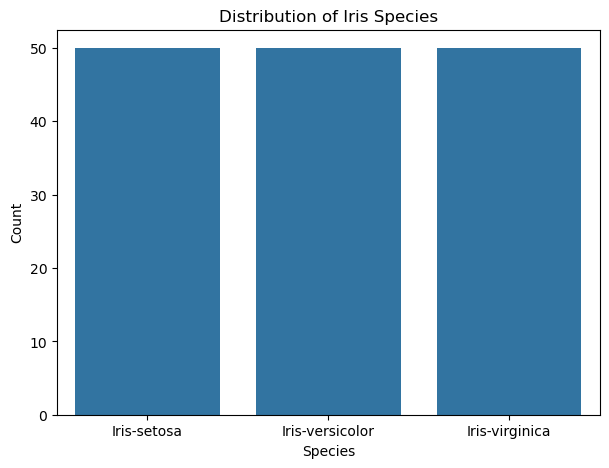

In [5]:
print("Species Distribution:")
print(df['Species'].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Species')
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

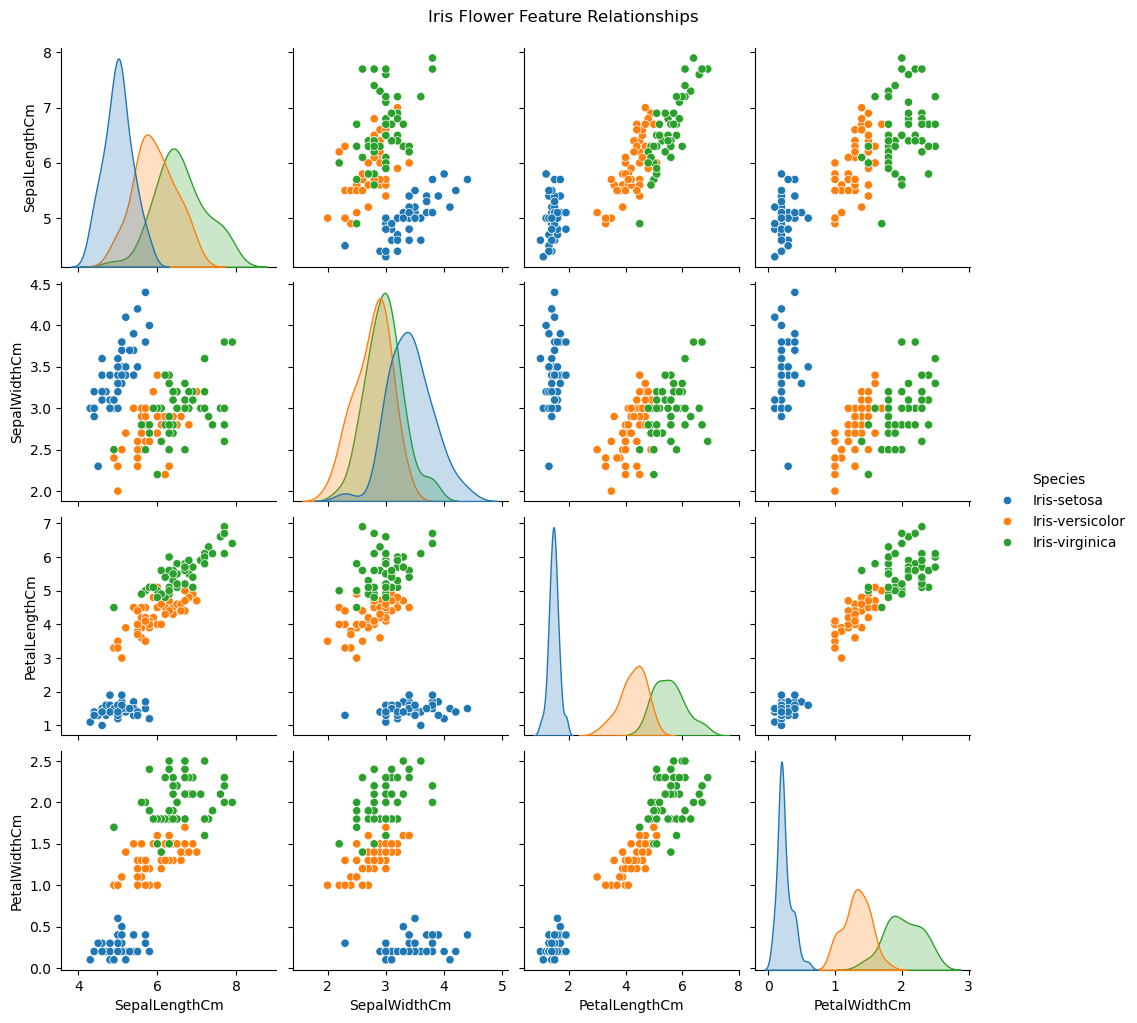

In [6]:
sns.pairplot(df, hue='Species')
plt.suptitle("Iris Flower Feature Relationships", y=1.02)
plt.show()

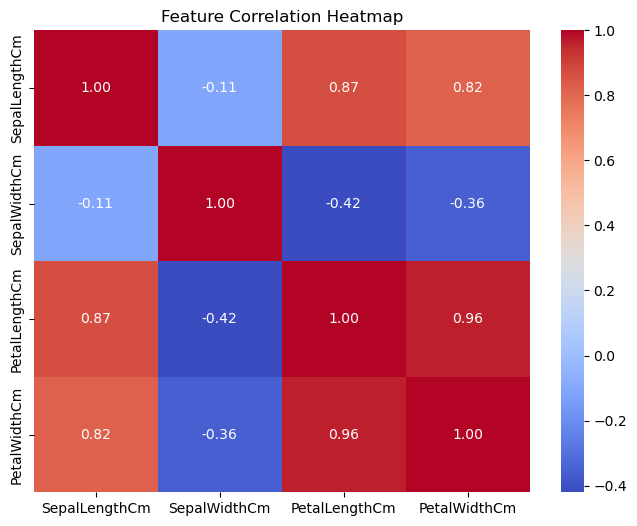

In [7]:
plt.figure(figsize=(8, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [8]:
X = df.drop('Species', axis=1)
y = df['Species']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 93.33 %
Decision Tree Accuracy: 90.0 %
KNN Accuracy: 93.33 %
Random Forest Accuracy: 90.0 %


In [12]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=['Model', 'Accuracy']
)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

display(results_df)

,Model,Accuracy
0,Logistic Regression,0.933333
2,KNN,0.933333
1,Decision Tree,0.900000
3,Random Forest,0.900000


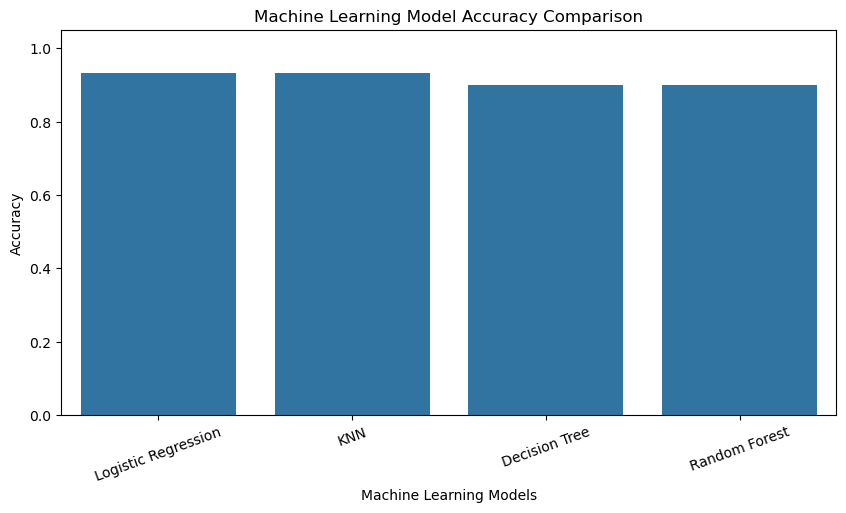

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)

plt.show()

In [14]:
best_model_name = results_df.iloc[0]['Model']

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print(
    "Best Accuracy:",
    round(results[best_model_name] * 100, 2),
    "%"
)

Best Model: Logistic Regression
Best Accuracy: 93.33 %


In [15]:
best_predictions = best_model.predict(X_test_scaled)

print("Classification Report:")
print(
    classification_report(
        y_test,
        best_predictions
    )
)

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



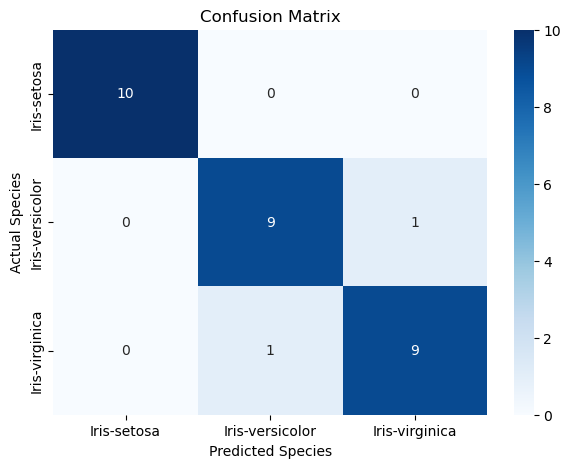

In [16]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=best_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [17]:
# Example flower measurements
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

new_flower_scaled = scaler.transform(new_flower)

prediction = best_model.predict(new_flower_scaled)

print("Predicted Iris Species:", prediction[0])

Predicted Iris Species: Iris-setosa


In [18]:
print("=" * 50)
print("IRIS FLOWER CLASSIFICATION PROJECT")
print("=" * 50)

print("Total Records:", len(df))
print("Total Features:", X.shape[1])
print("Number of Species:", y.nunique())

print("\nModels Evaluated:")
for name, accuracy in results.items():
    print(f"{name}: {accuracy * 100:.2f}%")

print("\nBest Performing Model:", best_model_name)
print("Best Accuracy:", round(
    results[best_model_name] * 100, 2
), "%")

print("\nProject Completed Successfully!")

IRIS FLOWER CLASSIFICATION PROJECT
Total Records: 150
Total Features: 4
Number of Species: 3

Models Evaluated:
Logistic Regression: 93.33%
Decision Tree: 90.00%
KNN: 93.33%
Random Forest: 90.00%

Best Performing Model: Logistic Regression
Best Accuracy: 93.33 %

Project Completed Successfully!
